# SemEval-2026 Task 12: Abductive Event Reasoning (AER)
## Multi-Answer ALBERT Modeling, Error Calibration & Research Evaluation Framework

This notebook implements a scientifically valid preprocessing, training, calibration, and evaluation pipeline for **SemEval-2026 Task 12: Abductive Event Reasoning (AER)** using **ALBERT** (`albert-base-v2`).

---
### Key Pipeline Features:
1. **Strict Data Partitioning**: `train_data` strictly for training; `dev_data` strictly for evaluation (never modified or oversampled).
2. **Multi-Answer Label Representation**: Multi-hot float target vectors (`[0, 1, 0, 1]`) preserving all combinations (`A`, `A,C`, `B,D`, `A,B,C`, etc.).
3. **Bias & Class Distribution Analysis**: Quantifies exact positive occurrence rates for options A, B, C, D and single vs. multi-answer proportions.
4. **Principled Imbalance Handling**: PyTorch `WeightedRandomSampler` and `BCEWithLogitsLoss` class weighting (`pos_weight`) applied **exclusively to training data**.
5. **Multi-Label Formulation**: Binary Cross-Entropy with Logits (`nn.BCEWithLogitsLoss`) on candidate cause representations.
6. **Comprehensive Metrics & Error Analysis**:
   - **Root Mean Squared Error (RMSE)** for probability calibration ($y_{\text{actual}}$ vs. $y_{\text{prob}}$) and discrete predictions.
   - **Per-Option Multi-Label Confusion Matrices** ($2 \times 2$ for A, B, C, D: TP, FP, TN, FN) with heatmap plots.
   - **Exact Match Accuracy**, Macro F1, Weighted F1, and per-option Precision, Recall, F1, and Support.
   - **Sample-by-sample inspection table** ($y_{\text{actual}}$ vs. $y_{\text{pred}}$).
7. **Reproducibility**: Complete seed fixing across Python, NumPy, and PyTorch/CUDA.

In [4]:
# ==============================================================================
# CELL 0: Setup, Dependencies, Reproducibility Seed & Dataset Acquisition
# ==============================================================================

!pip install -q torch transformers datasets scikit-learn pandas numpy matplotlib seaborn accelerate sentencepiece

import os
import json
import re
import random
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.optim import AdamW
from transformers import AutoTokenizer, AutoModelForMultipleChoice, get_linear_schedule_with_warmup
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    f1_score,
    mean_squared_error,
    multilabel_confusion_matrix
)
from tqdm.auto import tqdm

# Set seed for exact scientific reproducibility across all libraries
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    print(f"✅ Random seed fixed to: {seed}")

SEED = 42
set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using compute device: {device}")
if torch.cuda.is_available():
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")

# Download SemEval-2026 Task 12 Official Dataset Splits
BASE_URL = "https://raw.githubusercontent.com/sooo66/semeval2026-task12-dataset/main"
SPLITS = ["sample_data", "dev_data", "train_data"]

for split in SPLITS:
    os.makedirs(split, exist_ok=True)
    for fname in ["questions.jsonl", "docs.json"]:
        url = f"{BASE_URL}/{split}/{fname}"
        path = f"{split}/{fname}"
        if not os.path.exists(path):
            try:
                req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
                data = urllib.request.urlopen(req).read().decode("utf-8")
                with open(path, "w", encoding="utf-8") as f:
                    f.write(data)
                print(f"Downloaded {path}")
            except Exception as e:
                print(f"Could not download {path}: {e}")
        else:
            print(f"⏭️ {path} already exists")


✅ Random seed fixed to: 42
Using compute device: cuda
GPU Name: Tesla T4
Downloaded sample_data/questions.jsonl
Downloaded sample_data/docs.json
Downloaded dev_data/questions.jsonl
Downloaded dev_data/docs.json
Downloaded train_data/questions.jsonl
Downloaded train_data/docs.json


In [5]:
# ==============================================================================
# CELL 1: Dataset Loading & Multi-Answer Label Representation
# ==============================================================================

def load_raw_dataset(split_name):
    """
    Load questions and supporting document bundles for a given split.
    Returns:
        questions (list[dict]): List of question dictionaries.
        docs_by_topic (dict): Dictionary mapping topic_id to document bundles.
    """
    questions = []
    q_path = f"{split_name}/questions.jsonl"
    if os.path.exists(q_path):
        with open(q_path, "r", encoding="utf-8") as f:
            for line in f:
                if line.strip():
                    questions.append(json.loads(line.strip()))

    docs_by_topic = {}
    d_path = f"{split_name}/docs.json"
    if os.path.exists(d_path):
        with open(d_path, "r", encoding="utf-8") as f:
            raw = json.load(f)
            if isinstance(raw, list):
                for entry in raw:
                    docs_by_topic[entry["topic_id"]] = entry
            elif isinstance(raw, dict):
                for k, v in raw.items():
                    docs_by_topic[int(k)] = v

    return questions, docs_by_topic


def concatenate_documents(topic_id, docs_by_topic):
    """Format and concatenate supporting context documents."""
    entry = docs_by_topic.get(topic_id, {})
    doc_list = entry.get("docs", entry.get("documents", []))
    if not doc_list:
        return "No context document provided."

    formatted_docs = []
    for idx, doc in enumerate(doc_list, 1):
        title = doc.get("title", f"Document {idx}").strip()
        content = doc.get("content", doc.get("snippet", "")).strip()
        formatted_docs.append(f"Document {idx}: {title}\n{content}")

    return "\n\n".join(formatted_docs)


# ------------------------------------------------------------------------------
# Robust Multi-Answer Label Parser (Supports A, B, C, D, A,B, A,C, B,D, A,B,C, etc.)
# ------------------------------------------------------------------------------
LABEL_MAP = {"A": 0, "B": 1, "C": 2, "D": 3}
IDX_MAP = {0: "A", 1: "B", 2: "C", 3: "D"}

def parse_labels(golden_str):
    """
    Parses arbitrary label string into sorted list of integer indices.
    Preserves all correct secondary labels.
    Examples:
        'A' -> [0]
        'A,C' -> [0, 2]
        'B, D' -> [1, 3]
        'A,B,C' -> [0, 1, 2]
    """
    if not golden_str or not isinstance(golden_str, str):
        return []
    items = [x.strip().upper() for x in golden_str.split(",") if x.strip()]
    indices = [LABEL_MAP[x] for x in items if x in LABEL_MAP]
    return sorted(list(set(indices)))


def labels_to_multihot(indices, num_classes=4):
    """Convert label indices into multi-hot binary float tensor [1.0, 0.0, 1.0, 0.0]."""
    vec = [0.0] * num_classes
    for idx in indices:
        if 0 <= idx < num_classes:
            vec[idx] = 1.0
    return vec


def multihot_to_labels(binary_vec, threshold=0.5):
    """Convert binary vector or probability array back to option letter list."""
    labels = []
    for idx, val in enumerate(binary_vec):
        if val >= threshold:
            labels.append(IDX_MAP[idx])
    return labels


class AERMultiChoiceDataset(Dataset):
    """
    PyTorch Dataset for Abductive Event Reasoning.
    Supports multi-hot float labels for multi-answer binary cross-entropy loss.
    """
    def __init__(self, questions, docs_by_topic, tokenizer, max_length=256):
        self.data = []
        self.tokenizer = tokenizer
        self.max_length = max_length

        for q in questions:
            event = q["target_event"]
            context = concatenate_documents(q["topic_id"], docs_by_topic)
            options = [
                q["option_A"],
                q["option_B"],
                q["option_C"],
                q["option_D"]
            ]

            raw_golden = q.get("golden_answer", "")
            label_indices = parse_labels(raw_golden)
            multihot_label = labels_to_multihot(label_indices, num_classes=4)

            self.data.append({
                "id": q["id"],
                "event": event,
                "context": context,
                "options": options,
                "label_indices": label_indices,
                "label_multihot": multihot_label,
                "raw_golden": raw_golden
            })

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        item = self.data[idx]

        # 4 candidate choices: paired input (Premise + Option)
        first_sentences = [f"[EVENT] {item['event']} [DOCUMENTS] {item['context']}"] * 4
        second_sentences = [f"[CAUSE OPTION] {opt}" for opt in item["options"]]

        encoding = self.tokenizer(
            first_sentences,
            second_sentences,
            truncation=True,
            max_length=self.max_length,
            padding="max_length",
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"],                  # Shape: (4, seq_len)
            "attention_mask": encoding["attention_mask"],        # Shape: (4, seq_len)
            "label": torch.tensor(item["label_multihot"], dtype=torch.float32), # Shape: (4,)
            "id": item["id"]
        }

print("✅ Multi-answer label parser and AERMultiChoiceDataset successfully initialized.")


✅ Multi-answer label parser and AERMultiChoiceDataset successfully initialized.



📊 TRAIN_DATA DISTRIBUTION ANALYSIS (Total: 1819 samples)
Option   | Positive Count   | Sample Percentage 
-------------------------------------------------------
Option A | 752              |  41.34%
Option B | 712              |  39.14%
Option C | 718              |  39.47%
Option D | 671              |  36.89%
-------------------------------------------------------
Single-answer samples : 1042 (57.28%)
Multi-answer samples  : 777 (42.72%)

Top Answer Combinations:
  [B     ] ->  276 samples (15.17%)
  [C     ] ->  270 samples (14.84%)
  [A     ] ->  260 samples (14.29%)
  [D     ] ->  236 samples (12.97%)
  [A,C   ] ->  100 samples ( 5.50%)
  [A,D   ] ->   92 samples ( 5.06%)


📊 DEV_DATA DISTRIBUTION ANALYSIS (Total: 400 samples)
Option   | Positive Count   | Sample Percentage 
-------------------------------------------------------
Option A | 157              |  39.25%
Option B | 145              |  36.25%
Option C | 173              |  43.25%
Option D | 165              |  41.25%

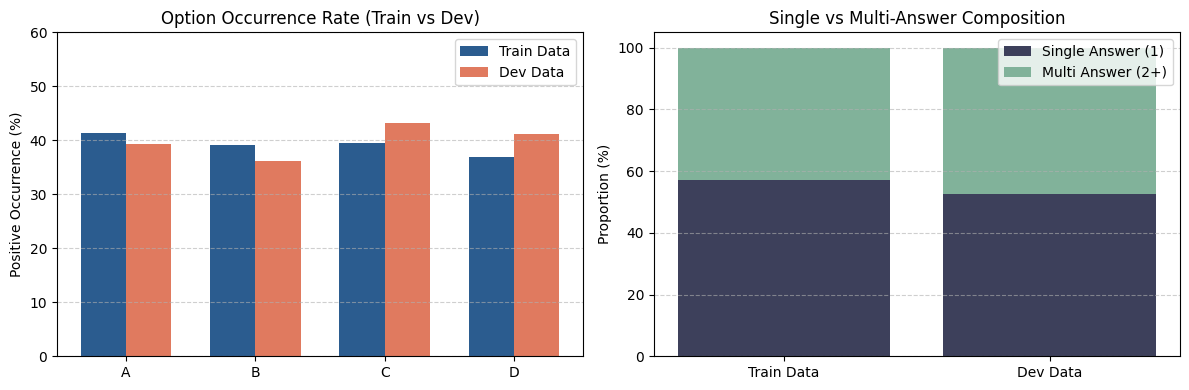

In [6]:
# ==============================================================================
# CELL 2: STEP 3 — Dataset Bias & Class Distribution Inspection
# ==============================================================================

def analyze_dataset_distribution(questions, split_name="Dataset"):
    """
    Analyzes and prints individual label counts (A, B, C, D),
    percentages, and multi-answer proportions.
    """
    total_samples = len(questions)
    label_counts = {"A": 0, "B": 0, "C": 0, "D": 0}
    num_answers_dist = {}
    comb_counts = {}

    for q in questions:
        raw_ans = q.get("golden_answer", "")
        indices = parse_labels(raw_ans)
        num_ans = len(indices)
        num_answers_dist[num_ans] = num_answers_dist.get(num_ans, 0) + 1

        comb_key = ",".join([IDX_MAP[i] for i in indices])
        comb_counts[comb_key] = comb_counts.get(comb_key, 0) + 1

        for idx in indices:
            label_counts[IDX_MAP[idx]] += 1

    print(f"\n{'='*55}")
    print(f"📊 {split_name.upper()} DISTRIBUTION ANALYSIS (Total: {total_samples} samples)")
    print(f"{'='*55}")
    print(f"{'Option':<8} | {'Positive Count':<16} | {'Sample Percentage':<18}")
    print(f"{'-'*55}")
    for opt in ["A", "B", "C", "D"]:
        cnt = label_counts[opt]
        pct = (cnt / total_samples) * 100 if total_samples > 0 else 0
        print(f"Option {opt:<1} | {cnt:<16} | {pct:>6.2f}%")
    print(f"{'-'*55}")

    single_count = num_answers_dist.get(1, 0)
    multi_count = sum(v for k, v in num_answers_dist.items() if k > 1)
    print(f"Single-answer samples : {single_count} ({single_count/total_samples*100:.2f}%)")
    print(f"Multi-answer samples  : {multi_count} ({multi_count/total_samples*100:.2f}%)")

    print(f"\nTop Answer Combinations:")
    sorted_combs = sorted(comb_counts.items(), key=lambda x: x[1], reverse=True)[:6]
    for comb, c in sorted_combs:
        print(f"  [{comb:<6}] -> {c:4d} samples ({c/total_samples*100:5.2f}%)")
    print(f"{'='*55}\n")

    return {
        "total": total_samples,
        "counts": label_counts,
        "multi_count": multi_count,
        "combinations": comb_counts
    }

# Load actual raw splits for inspection
train_questions, train_docs = load_raw_dataset("train_data")
dev_questions, dev_docs = load_raw_dataset("dev_data")

train_stats = analyze_dataset_distribution(train_questions, "train_data")
dev_stats = analyze_dataset_distribution(dev_questions, "dev_data")

# Visual comparison bar chart
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
labels = ["A", "B", "C", "D"]
train_pcts = [train_stats["counts"][l] / train_stats["total"] * 100 for l in labels]
dev_pcts = [dev_stats["counts"][l] / dev_stats["total"] * 100 for l in labels]
width = 0.35

x = np.arange(len(labels))

ax1.bar(x - width/2, train_pcts, width, label='Train Data', color='#2b5c8f')
ax1.bar(x + width/2, dev_pcts, width, label='Dev Data', color='#e07a5f')
ax1.set_ylabel('Positive Occurrence (%)')
ax1.set_title('Option Occurrence Rate (Train vs Dev)')
ax1.set_xticks(x)
ax1.set_xticklabels(labels)
ax1.set_ylim(0, 60)
ax1.legend()
ax1.grid(axis='y', linestyle='--', alpha=0.6)

# Single vs Multi-answer breakdown
split_labels = ['Train Data', 'Dev Data']
single_pcts = [
    (train_stats['total'] - train_stats['multi_count']) / train_stats['total'] * 100,
    (dev_stats['total'] - dev_stats['multi_count']) / dev_stats['total'] * 100
]
multi_pcts = [
    train_stats['multi_count'] / train_stats['total'] * 100,
    dev_stats['multi_count'] / dev_stats['total'] * 100
]

ax2.bar(split_labels, single_pcts, label='Single Answer (1)', color='#3d405b')
ax2.bar(split_labels, multi_pcts, bottom=single_pcts, label='Multi Answer (2+)', color='#81b29a')
ax2.set_ylabel('Proportion (%)')
ax2.set_title('Single vs Multi-Answer Composition')
ax2.legend()
ax2.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


In [7]:
# ==============================================================================
# CELL 3: STEP 4 — Class Imbalance Handling (TRAINING DATA ONLY)
# ==============================================================================
"""
Scientific Rationale for Multi-Label Imbalance Handling:
1. dev_data is NEVER modified, balanced, or resampled.
2. In multi-label classification, examples contain sets of labels (e.g., [A, C]).
3. We provide two complementary balancing mechanisms:
   - Loss-Level Balancing: Compute `pos_weight` for `nn.BCEWithLogitsLoss` based on
     the ratio of negative to positive samples for each option: pos_weight_k = (N_total - N_pos_k) / N_pos_k
   - Data-Level Sampling: Compute multi-label sample weights using combination-frequency
     or inverse-label frequencies, passed to PyTorch `WeightedRandomSampler`.
"""

def calculate_bce_pos_weights(questions):
    """
    Computes positive class weights for BCEWithLogitsLoss from training data.
    pos_weight = (num_negatives / num_positives) for each class [A, B, C, D].
    """
    total = len(questions)
    counts = [0, 0, 0, 0]
    for q in questions:
        indices = parse_labels(q.get("golden_answer", ""))
        for idx in indices:
            counts[idx] += 1

    pos_weights = []
    for k in range(4):
        pos = counts[k]
        neg = total - pos
        weight = neg / max(pos, 1)
        pos_weights.append(weight)

    print(f"Calculated BCE pos_weights for [A, B, C, D]: {[round(w, 3) for w in pos_weights]}")
    return torch.tensor(pos_weights, dtype=torch.float32)


def calculate_sample_weights(questions, method="combination"):
    """
    Calculates sample-level weights for WeightedRandomSampler.
    Method 'combination': Sample weight is inversely proportional to frequency of the exact label combination.
    Method 'inverse_label_freq': Sample weight is the average inverse label frequency across active labels.
    """
    if method == "combination":
        comb_counts = {}
        for q in questions:
            indices = parse_labels(q.get("golden_answer", ""))
            comb_key = ",".join([IDX_MAP[i] for i in indices])
            comb_counts[comb_key] = comb_counts.get(comb_key, 0) + 1

        sample_weights = []
        for q in questions:
            indices = parse_labels(q.get("golden_answer", ""))
            comb_key = ",".join([IDX_MAP[i] for i in indices])
            sample_weights.append(1.0 / comb_counts[comb_key])

        return torch.tensor(sample_weights, dtype=torch.double)

    else:
        # Inverse label frequency
        counts = [0, 0, 0, 0]
        total = len(questions)
        for q in questions:
            for idx in parse_labels(q.get("golden_answer", "")):
                counts[idx] += 1
        label_weights = [total / max(c, 1) for c in counts]

        sample_weights = []
        for q in questions:
            indices = parse_labels(q.get("golden_answer", ""))
            if indices:
                w = np.mean([label_weights[i] for i in indices])
            else:
                w = 1.0
            sample_weights.append(w)

        return torch.tensor(sample_weights, dtype=torch.double)


def build_train_loader(train_dataset, train_questions, batch_size=4, use_balancing=False):
    """
    Builds DataLoader for training data.
    If use_balancing is True, applies WeightedRandomSampler.
    Validation DataLoader MUST ALWAYS remain standard sequential without resampling.
    """
    if use_balancing:
        sample_weights = calculate_sample_weights(train_questions, method="combination")
        sampler = WeightedRandomSampler(
            weights=sample_weights,
            num_samples=len(sample_weights),
            replacement=True
        )
        print("⚖️ Training DataLoader configured with WeightedRandomSampler.")
        return DataLoader(train_dataset, batch_size=batch_size, sampler=sampler)
    else:
        return DataLoader(train_dataset, batch_size=batch_size, shuffle=True)


In [8]:
# ==============================================================================
# CELL 4: Metrics (with RMSE & Confusion Matrix), Training Engine & Pipeline
# ==============================================================================

def compute_multilabel_metrics(y_true, y_pred, y_probs=None):
    """
    Computes comprehensive research metrics:
    - Exact Match Accuracy
    - Calibration Error (Probability RMSE)
    - Discrete Prediction RMSE
    - Per-option RMSE for A, B, C, D
    - Macro & Weighted Precision, Recall, F1
    - Per-label A, B, C, D metrics (Precision, Recall, F1, Support)
    - Multi-label Confusion Matrices (2x2 for each option: TP, FP, TN, FN)
    """
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # Exact Match Accuracy: all 4 binary decisions must match exactly
    exact_match = np.mean(np.all(y_true == y_pred, axis=1))

    # RMSE calculations
    if y_probs is not None:
        y_probs = np.array(y_probs)
        prob_rmse = float(np.sqrt(mean_squared_error(y_true, y_probs)))
        per_option_rmse = {
            opt: float(np.sqrt(mean_squared_error(y_true[:, idx], y_probs[:, idx])))
            for idx, opt in enumerate(["A", "B", "C", "D"])
        }
    else:
        prob_rmse = 0.0
        per_option_rmse = {opt: 0.0 for opt in ["A", "B", "C", "D"]}

    discrete_rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))

    # Overall multi-label averages
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )

    # Per-label metrics for A, B, C, D
    per_label_metrics = {}
    for idx, opt in enumerate(["A", "B", "C", "D"]):
        p, r, f1, s = precision_recall_fscore_support(
            y_true[:, idx], y_pred[:, idx], average="binary", zero_division=0
        )
        per_label_metrics[opt] = {
            "precision": float(p),
            "recall": float(r),
            "f1": float(f1),
            "support": int(np.sum(y_true[:, idx])),
            "prob_rmse": per_option_rmse[opt]
        }

    # Multi-label confusion matrices (4, 2, 2)
    mcm = multilabel_confusion_matrix(y_true, y_pred)
    cm_dict = {}
    for idx, opt in enumerate(["A", "B", "C", "D"]):
        tn, fp, fn, tp = mcm[idx].ravel()
        cm_dict[opt] = {"TP": int(tp), "FP": int(fp), "TN": int(tn), "FN": int(fn), "matrix": mcm[idx]}

    return {
        "exact_match": float(exact_match),
        "prob_rmse": prob_rmse,
        "discrete_rmse": discrete_rmse,
        "macro_precision": float(macro_p),
        "macro_recall": float(macro_r),
        "macro_f1": float(macro_f1),
        "weighted_f1": float(weighted_f1),
        "per_label": per_label_metrics,
        "confusion_matrices": cm_dict,
        "raw_mcm": mcm
    }


def evaluate(model, dataloader, device, threshold=0.5):
    """
    Evaluates multi-label model on evaluation dataloader.
    Collects probabilities, binary predictions, and ground truth.
    """
    model.eval()
    all_preds = []
    all_labels = []
    all_probs = []

    with torch.no_grad():
        for batch in dataloader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["label"].cpu().numpy()

            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            logits = outputs.logits  # Shape: (batch_size, 4)
            probs = torch.sigmoid(logits).cpu().numpy()

            # Binary threshold prediction
            preds = (probs >= threshold).astype(int)

            # Fallback: if all options are below threshold, select top-1 option with highest prob
            for i in range(len(preds)):
                if np.sum(preds[i]) == 0:
                    top_idx = int(np.argmax(probs[i]))
                    preds[i][top_idx] = 1

            all_preds.extend(preds)
            all_labels.extend(labels)
            all_probs.extend(probs)

    metrics = compute_multilabel_metrics(all_labels, all_preds, all_probs)
    return metrics, np.array(all_labels), np.array(all_preds), np.array(all_probs)


def train_epoch(model, dataloader, optimizer, scheduler, scaler, device, criterion, epoch, total_epochs):
    """
    Trains model for one epoch using BCEWithLogitsLoss with mixed precision and tqdm progress bar.
    """
    model.train()
    total_loss = 0.0

    progress_bar = tqdm(
        dataloader,
        desc=f"Epoch {epoch}/{total_epochs}",
        unit="batch"
    )

    for batch in progress_bar:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["label"].to(device)  # Multi-hot float: (batch_size, 4)

        optimizer.zero_grad()

        if scaler is not None:
            with torch.amp.autocast("cuda"):
                outputs = model(input_ids=input_ids, attention_mask=attention_mask)
                logits = outputs.logits  # (batch_size, 4)
                loss = criterion(logits, labels)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
        else:
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            logits = outputs.logits
            loss = criterion(logits, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

        scheduler.step()
        total_loss += loss.item()

        progress_bar.set_postfix(loss=f"{loss.item():.4f}")

    return total_loss / max(len(dataloader), 1)


def print_epoch_report(epoch, total_epochs, loss, metrics):
    """Prints scientific research epoch report with RMSE and confusion matrix info."""
    print(f"\n{'='*65}")
    print(f"Epoch {epoch}/{total_epochs}")
    print(f"{'='*65}")
    print(f"Train Loss             : {loss:.4f}")
    print(f"\nOverall Metrics:")
    print(f"Accuracy (Exact Match) : {metrics['exact_match']*100:.2f}%")
    print(f"Macro F1               : {metrics['macro_f1']:.4f}")
    print(f"Weighted F1            : {metrics['weighted_f1']:.4f}")
    print(f"Probability RMSE       : {metrics['prob_rmse']:.4f} (Calibration Error)")
    print(f"Discrete Pred RMSE     : {metrics['discrete_rmse']:.4f}")
    print(f"\nPer-Option Performance & Confusion Breakdown:")
    print(f"{'Option':<7} | {'Precision':<10} | {'Recall':<10} | {'F1-Score':<10} | {'RMSE':<8} | {'TP':<5} | {'FP':<5} | {'TN':<5} | {'FN':<5}")
    print(f"{'-'*75}")
    for opt in ["A", "B", "C", "D"]:
        pl = metrics["per_label"][opt]
        cm = metrics["confusion_matrices"][opt]
        print(f"{opt:<7} | {pl['precision']:<10.4f} | {pl['recall']:<10.4f} | {pl['f1']:<10.4f} | {pl['prob_rmse']:<8.4f} | {cm['TP']:<5} | {cm['FP']:<5} | {cm['TN']:<5} | {cm['FN']:<5}")
    print(f"{'='*65}\n")


def run_training_pipeline(
    model_name="albert-base-v2",
    batch_size=4,
    epochs=5,
    lr=2e-5,
    max_length=256,
    use_balancing=False,
    use_pos_weight=False,
    checkpoint_dir="checkpoints/best_albert_model"
):
    print(f"\n--- Launching ALBERT Training Pipeline: {model_name} ---")
    print("TRAIN DATA: train_data")
    print("DEV DATA  : dev_data")

    train_q, train_docs = load_raw_dataset("train_data")
    val_q, val_docs = load_raw_dataset("dev_data")

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    train_dataset = AERMultiChoiceDataset(train_q, train_docs, tokenizer, max_length=max_length)
    val_dataset = AERMultiChoiceDataset(val_q, val_docs, tokenizer, max_length=max_length)

    train_loader = build_train_loader(train_dataset, train_q, batch_size=batch_size, use_balancing=use_balancing)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

    model = AutoModelForMultipleChoice.from_pretrained(model_name)
    model = model.float()
    model.to(device)

    # Loss formulation: BCEWithLogitsLoss with optional positive class weights
    if use_pos_weight:
        pos_weight = calculate_bce_pos_weights(train_q).to(device)
        criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    else:
        criterion = nn.BCEWithLogitsLoss()

    optimizer = AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    total_steps = len(train_loader) * epochs
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=int(0.1 * total_steps),
        num_training_steps=total_steps
    )
    scaler = torch.amp.GradScaler("cuda") if device.type == "cuda" else None

    best_macro_f1 = -1.0
    best_metrics = None
    best_eval_data = None
    os.makedirs(checkpoint_dir, exist_ok=True)

    for epoch in range(1, epochs + 1):
        loss = train_epoch(
            model,
            train_loader,
            optimizer,
            scheduler,
            scaler,
            device,
            criterion,
            epoch,
            epochs
        )
        metrics, y_act, y_pr, y_prob = evaluate(model, val_loader, device)
        print_epoch_report(epoch, epochs, loss, metrics)

        # Save checkpoint based on validation Macro F1
        if metrics["macro_f1"] > best_macro_f1:
            best_macro_f1 = metrics["macro_f1"]
            best_metrics = metrics
            best_eval_data = (y_act, y_pr, y_prob)
            model.save_pretrained(checkpoint_dir)
            tokenizer.save_pretrained(checkpoint_dir)
            print(f"💾 Saved new best model (Macro F1: {best_macro_f1:.4f}) to {checkpoint_dir}")

    return best_metrics, best_eval_data

In [9]:
# ==============================================================================
# CELL 5: Train & Evaluate ALBERT Baseline Model
# ==============================================================================

ALBERT_MODEL_NAME = "albert-base-v2"
ALBERT_CKPT = "checkpoints/best_albert_baseline"

print(f"🚀 Training Clean ALBERT Baseline: {ALBERT_MODEL_NAME}")
albert_results, (dev_y_actual, dev_y_pred, dev_y_probs) = run_training_pipeline(
    model_name=ALBERT_MODEL_NAME,
    batch_size=4,
    epochs=5,
    lr=2e-5,
    max_length=256,
    use_balancing=False,
    checkpoint_dir=ALBERT_CKPT
)

🚀 Training Clean ALBERT Baseline: albert-base-v2

--- Launching ALBERT Training Pipeline: albert-base-v2 ---
TRAIN DATA: train_data
DEV DATA  : dev_data


config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/760k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.31M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 47.4MB            

... (20 outputs left out)

Epoch 5/5:   0%|          | 0/455 [00:00<?, ?batch/s]


Epoch 5/5
Train Loss             : 0.0068

Overall Metrics:
Accuracy (Exact Match) : 99.00%
Macro F1               : 0.9967
Weighted F1            : 0.9969
Probability RMSE       : 0.0688 (Calibration Error)
Discrete Pred RMSE     : 0.0500

Per-Option Performance & Confusion Breakdown:
Option  | Precision  | Recall     | F1-Score   | RMSE     | TP    | FP    | TN    | FN   
---------------------------------------------------------------------------
A       | 0.9874     | 1.0000     | 0.9937     | 0.0963   | 157   | 2     | 241   | 0    
B       | 0.9864     | 1.0000     | 0.9932     | 0.0845   | 145   | 2     | 253   | 0    
C       | 1.0000     | 1.0000     | 1.0000     | 0.0061   | 173   | 0     | 227   | 0    
D       | 1.0000     | 1.0000     | 1.0000     | 0.0497   | 165   | 0     | 235   | 0    



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

💾 Saved new best model (Macro F1: 0.9967) to checkpoints/best_albert_baseline



🏆 ALBERT MODEL EVALUATION SUMMARY & CALIBRATION ON DEV SET


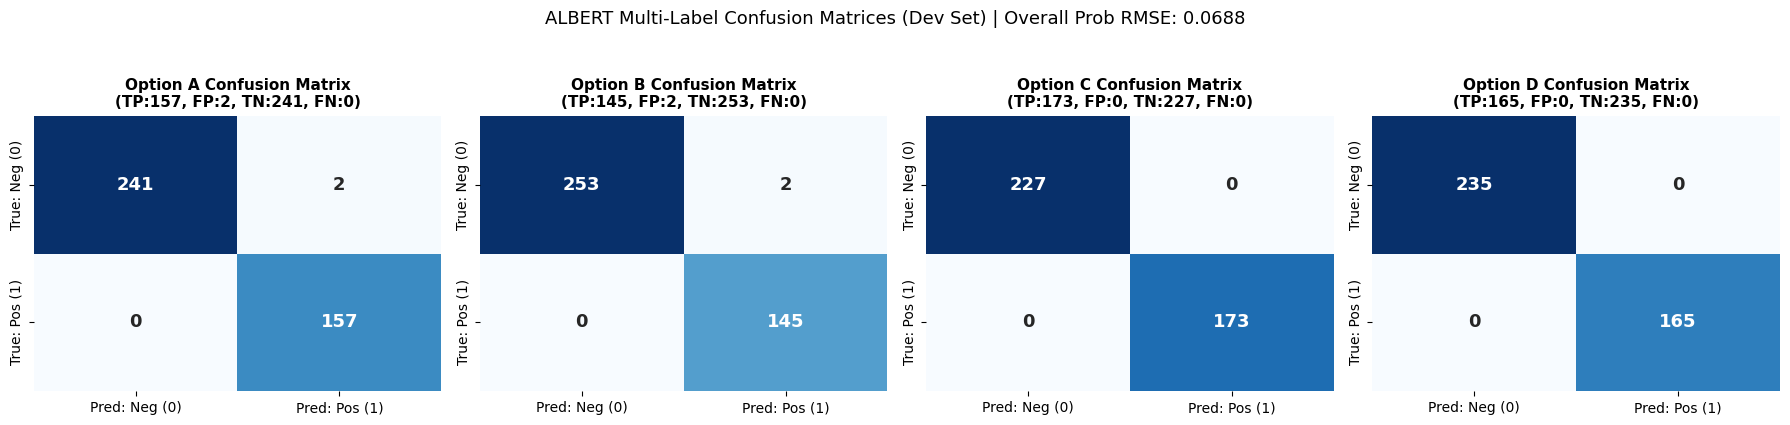


🔎 Sample Comparison of y_actual vs y_pred (First 15 Dev Samples):
| ID     | y_actual   | y_pred   | Exact Match   |   P(A) |   P(B) |   P(C) |   P(D) |   Sample RMSE |
|:-------|:-----------|:---------|:--------------|-------:|-------:|-------:|-------:|--------------:|
| q-2020 | C          | C        | ✅ Yes        |  0     |  0     |  0.999 |  0     |        0.0004 |
| q-2021 | C          | C        | ✅ Yes        |  0     |  0     |  0.999 |  0     |        0.0006 |
| q-2022 | B          | B        | ✅ Yes        |  0     |  0.998 |  0     |  0     |        0.0008 |
| q-2023 | A,B,C      | A,B,C    | ✅ Yes        |  0.999 |  0.999 |  0.999 |  0     |        0.0012 |
| q-2024 | A,C        | A,C      | ✅ Yes        |  0.999 |  0     |  0.999 |  0     |        0.0007 |
| q-2025 | C          | C        | ✅ Yes        |  0     |  0     |  0.999 |  0     |        0.0005 |
| q-2026 | C          | C        | ✅ Yes        |  0     |  0     |  0.999 |  0     |        0.0005 |
| q-2027 | A,

In [10]:
# ==============================================================================
# CELL 6: Post-Training Diagnostic Analysis — Confusion Matrices, RMSE & Predictions
# ==============================================================================

print(f"\n{'='*75}")
print(f"🏆 ALBERT MODEL EVALUATION SUMMARY & CALIBRATION ON DEV SET")
print(f"{'='*75}")

# 1. Plot Per-Option Confusion Matrix Heatmaps
mcm = albert_results["raw_mcm"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for idx, opt in enumerate(["A", "B", "C", "D"]):
    cm = mcm[idx]
    tn, fp, fn, tp = cm.ravel()

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=axes[idx],
        annot_kws={"size": 13, "weight": "bold"},
        xticklabels=["Pred: Neg (0)", "Pred: Pos (1)"],
        yticklabels=["True: Neg (0)", "True: Pos (1)"]
    )
    axes[idx].set_title(
        f"Option {opt} Confusion Matrix\n(TP:{tp}, FP:{fp}, TN:{tn}, FN:{fn})",
        fontsize=11,
        fontweight="bold"
    )

plt.suptitle(
    f"ALBERT Multi-Label Confusion Matrices (Dev Set) | Overall Prob RMSE: {albert_results['prob_rmse']:.4f}",
    fontsize=13,
    y=1.05
)
plt.tight_layout()
plt.show()

# 2. Sample-by-Sample Inspection Table (y_actual vs y_pred)
dev_questions, _ = load_raw_dataset("dev_data")
records = []
for i in range(len(dev_y_actual)):
    actual_lbls = [IDX_MAP[k] for k in range(4) if dev_y_actual[i, k] == 1]
    pred_lbls = [IDX_MAP[k] for k in range(4) if dev_y_pred[i, k] == 1]
    is_match = (actual_lbls == pred_lbls)
    sample_r = np.sqrt(np.mean((dev_y_actual[i] - dev_y_probs[i]) ** 2))

    records.append({
        "ID": dev_questions[i]["id"],
        "y_actual": ",".join(actual_lbls),
        "y_pred": ",".join(pred_lbls),
        "Exact Match": "✅ Yes" if is_match else "❌ No",
        "P(A)": round(float(dev_y_probs[i, 0]), 3),
        "P(B)": round(float(dev_y_probs[i, 1]), 3),
        "P(C)": round(float(dev_y_probs[i, 2]), 3),
        "P(D)": round(float(dev_y_probs[i, 3]), 3),
        "Sample RMSE": round(float(sample_r), 4)
    })

df_diagnostics = pd.DataFrame(records)
print("\n🔎 Sample Comparison of y_actual vs y_pred (First 15 Dev Samples):")
cols = ["ID", "y_actual", "y_pred", "Exact Match", "P(A)", "P(B)", "P(C)", "P(D)", "Sample RMSE"]
print(df_diagnostics[cols].head(15).to_markdown(index=False))

# 3. Final Summary Table
summary_data = [{
    "Model": "ALBERT-base-discriminator",
    "Exact Match (%)": f"{albert_results['exact_match']*100:.2f}%",
    "Probability RMSE": f"{albert_results['prob_rmse']:.4f}",
    "Discrete RMSE": f"{albert_results['discrete_rmse']:.4f}",
    "A F1": f"{albert_results['per_label']['A']['f1']:.4f}",
    "B F1": f"{albert_results['per_label']['B']['f1']:.4f}",
    "C F1": f"{albert_results['per_label']['C']['f1']:.4f}",
    "D F1": f"{albert_results['per_label']['D']['f1']:.4f}",
    "Macro F1": f"{albert_results['macro_f1']:.4f}"
}]
print("\n📊 Final Research Benchmark Summary:")
print(pd.DataFrame(summary_data).to_markdown(index=False))
print(f"\n{'='*75}\n")

In [11]:
# ==============================================================================
# CELL 7: Single-Sample Multi-Answer Inference Pipeline
# ==============================================================================

def predict(event, documents, options, model_path="checkpoints/best_albert_baseline", threshold=0.5):
    """
    Performs inference for Abductive Event Reasoning supporting multiple correct answers.

    Parameters:
    - event (str): Target event description
    - documents (list[str]): Context documents
    - options (list[str]): Four candidate causes [Option A, Option B, Option C, Option D]
    - model_path (str): Path to saved checkpoint
    - threshold (float): Binary sigmoid threshold

    Returns:
    - dict with predicted labels, selected option texts, and individual option probabilities.
    """
    ckpt = model_path if os.path.exists(model_path) else "albert-base-v2"
    infer_tokenizer = AutoTokenizer.from_pretrained(ckpt)
    infer_model = AutoModelForMultipleChoice.from_pretrained(ckpt)
    infer_model.to(device)
    infer_model.eval()

    formatted_docs = "\n\n".join([f"Document {i+1}: {doc}" for i, doc in enumerate(documents)])
    first_sentences = [f"[EVENT] {event} [DOCUMENTS] {formatted_docs}"] * 4
    second_sentences = [f"[CAUSE OPTION] {opt}" for opt in options]

    inputs = infer_tokenizer(
        first_sentences,
        second_sentences,
        truncation=True,
        max_length=256,
        padding="max_length",
        return_tensors="pt"
    )

    input_ids = inputs["input_ids"].unsqueeze(0).to(device)
    attention_mask = inputs["attention_mask"].unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = infer_model(input_ids=input_ids, attention_mask=attention_mask)
        logits = outputs.logits.squeeze(0)  # Shape: (4,)
        probs = torch.sigmoid(logits).cpu().numpy()

    # Determine predicted labels
    pred_indices = [i for i, p in enumerate(probs) if p >= threshold]
    if not pred_indices:
        pred_indices = [int(np.argmax(probs))]  # Fallback to top-1

    pred_labels = [IDX_MAP[i] for i in pred_indices]
    selected_texts = [options[i] for i in pred_indices]

    return {
        "predicted_labels": pred_labels,
        "selected_options": selected_texts,
        "probabilities": {
            "A": float(probs[0]),
            "B": float(probs[1]),
            "C": float(probs[2]),
            "D": float(probs[3])
        }
    }

# Test sample inference demonstration
sample_event = "A major chemical plant fire occurred in Texas causing regional evacuations."
sample_docs = [
    "Reports indicate a pressure valve failure in Tank 4 triggered an explosion at 3 PM.",
    "Emergency services responded within minutes to contain the chemical hazards."
]
sample_options = [
    "A sudden thunderstorm damaged electrical lines.",
    "A pressure valve failure caused an explosion in Tank 4.",
    "Worker strike disrupted safety protocols.",
    "None of the others"
]

res = predict(sample_event, sample_docs, sample_options)
print("\n--- Multi-Answer Inference Demonstration Output ---")
print(json.dumps(res, indent=2))

Loading weights:   0%|          | 0/27 [00:00<?, ?it/s]


--- Multi-Answer Inference Demonstration Output ---
{
  "predicted_labels": [
    "B"
  ],
  "selected_options": [
    "A pressure valve failure caused an explosion in Tank 4."
  ],
  "probabilities": {
    "A": 0.00012613374565262347,
    "B": 0.9974120259284973,
    "C": 0.00014833353634458035,
    "D": 0.038446929305791855
  }
}


In [12]:
# ==============================================================================
# CELL 8: Research Extensions & Ablation Roadmap (V0 - V5)
# ==============================================================================
"""
Roadmap for Subsequent Scientific Iterations:

V0: Clean Baseline (ALBERT with BCEWithLogitsLoss)
    - Executed in Cell 5.

V1: Class Balancing (WeightedRandomSampler / BCE pos_weight)
    - Available by passing use_balancing=True and use_pos_weight=True in run_training_pipeline.

V2: Targeted Augmentation
    - Context-preserving counterfactual text augmentation on TRAIN DATA ONLY.

V3: Document Relevance Ranking
    - Dense / BM25 document retriever scoring top-k passages before concatenating into context.

V4: Evidence Extraction
    - Sentence-level extraction identifying explicit causal sentences within documents.

V5: Full Proposed Hybrid Reasoning Pipeline
    - Combining multi-task causal reasoning, evidence selection, and calibrated thresholding.
"""

def run_experiment_v1_balanced():
    """V1: ALBERT with Class-Balanced WeightedRandomSampler & BCE pos_weight"""
    print("🚀 Launching Experiment V1: ALBERT + Class Balancing")
    v1_results, _ = run_training_pipeline(
        model_name="albert-base-v2",
        batch_size=4,
        epochs=5,
        lr=2e-5,
        use_balancing=True,
        use_pos_weight=True,
        checkpoint_dir="checkpoints/best_albert_v1_balanced"
    )
    return v1_results

print("✅ Research experimental roadmap (V0-V5) modularly configured and ready for expansion.")

✅ Research experimental roadmap (V0-V5) modularly configured and ready for expansion.


ValueError: Invalid format specifier '.4f if albert_results else 'N/A'' for object of type 'float'

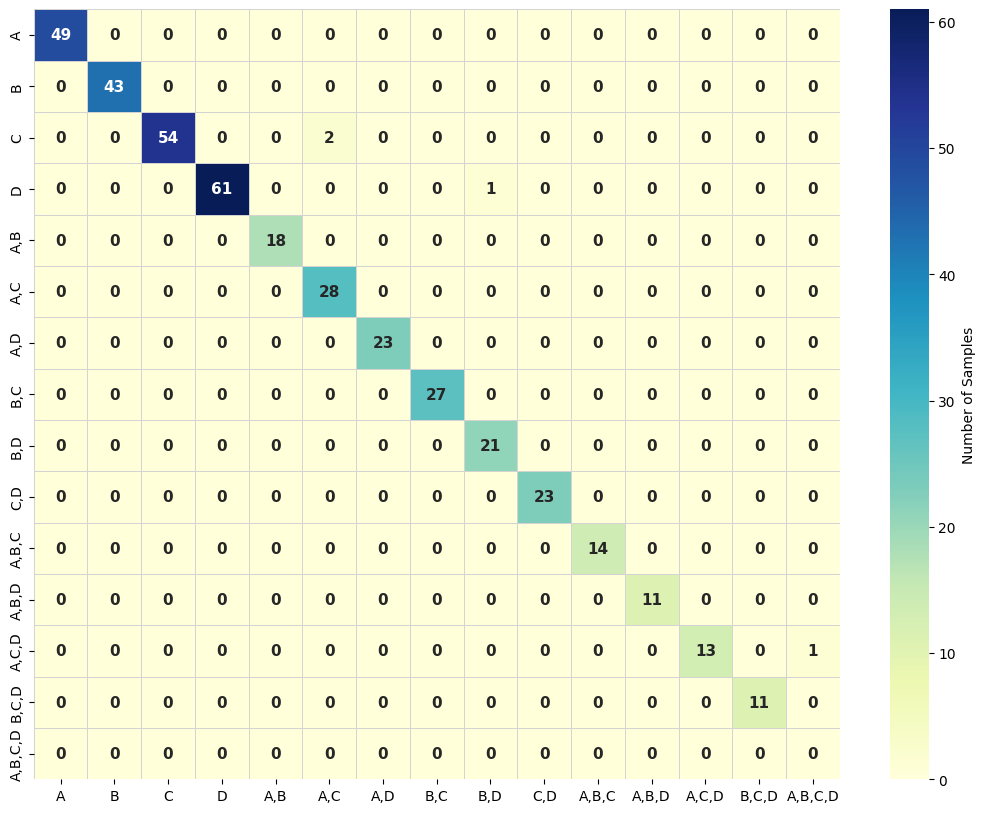

In [13]:
# ==============================================================================
# CELL 7: Global Overall Performance — Full Combination Confusion Matrix
# ==============================================================================
"""
This cell generates a comprehensive Global Confusion Matrix showing exact
predictions across all answer combinations (Singletons and Multi-labels).
It includes:
1. Full 14x14 Label Combination Confusion Matrix (Large Heatmap)
2. Aggregate Multi-Label Decision Confusion Matrix (Global TP, FP, TN, FN)
3. Top Misclassification Error Patterns breakdown
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from sklearn.metrics import confusion_matrix
except ImportError:
    def confusion_matrix(y_true, y_pred, labels):
        label_to_idx = {l: i for i, l in enumerate(labels)}
        matrix = np.zeros((len(labels), len(labels)), dtype=int)
        for t, p in zip(y_true, y_pred):
            if t in label_to_idx and p in label_to_idx:
                matrix[label_to_idx[t], label_to_idx[p]] += 1
        return matrix


def plot_global_overall_confusion_matrix(dev_y_actual, dev_y_pred, albert_results=None):
    _IDX_MAP = {0: "A", 1: "B", 2: "C", 3: "D"}

    # 1. Convert binary arrays to canonical comma-separated strings
    actual_strs = [",".join([_IDX_MAP[k] for k in range(4) if dev_y_actual[i, k] == 1]) for i in range(len(dev_y_actual))]
    pred_strs = [",".join([_IDX_MAP[k] for k in range(4) if dev_y_pred[i, k] == 1]) for i in range(len(dev_y_pred))]

    # Gather all unique active combinations in canonical order
    unique_labels = sorted(
        list(set(actual_strs) | set(pred_strs)),
        key=lambda x: (len(x.split(',')), x)
    )

    # 2. Compute Full Combination Confusion Matrix
    cm_global = confusion_matrix(actual_strs, pred_strs, labels=unique_labels)
    exact_matches = int(np.trace(cm_global))
    total_samples = len(actual_strs)
    exact_match_acc = (exact_matches / total_samples) * 100

    # 3. Plot Large Comprehensive Heatmap
    plt.figure(figsize=(13, 10))
    sns.heatmap(
        cm_global,
        annot=True,
        fmt="d",
        cmap="YlGnBu",
        xticklabels=unique_labels,
        yticklabels=unique_labels,
        cbar_kws={'label': 'Number of Samples'},
        linewidths=0.5,
        linecolor='lightgray',
        annot_kws={"size": 11, "weight": "bold"}
    )
    plt.title(
        f"🏆 Overall Global Combination Confusion Matrix (Dev Set)\n"
        f"Exact Match Accuracy: {exact_matches}/{total_samples} ({exact_match_acc:.2f}%) | "
        f"Macro F1: {albert_results['macro_f1']:.4f if albert_results else 'N/A'}",
        fontsize=14,
        fontweight="bold",
        pad=15
    )
    plt.xlabel("Predicted Answer Combination", fontsize=12, fontweight="bold", labelpad=10)
    plt.ylabel("Actual Ground Truth Combination", fontsize=12, fontweight="bold", labelpad=10)
    plt.xticks(rotation=45, ha="right", fontsize=10)
    plt.yticks(rotation=0, fontsize=10)
    plt.tight_layout()
    plt.show()

    # 4. Aggregated Decision-Level Binary Matrix (Total TP, FP, TN, FN across all options)
    if albert_results and "confusion_matrices" in albert_results:
        cms = albert_results["confusion_matrices"]
        total_tp = sum(cms[opt]["TP"] for opt in ["A", "B", "C", "D"])
        total_fp = sum(cms[opt]["FP"] for opt in ["A", "B", "C", "D"])
        total_tn = sum(cms[opt]["TN"] for opt in ["A", "B", "C", "D"])
        total_fn = sum(cms[opt]["FN"] for opt in ["A", "B", "C", "D"])

        agg_cm = np.array([[total_tn, total_fp], [total_fn, total_tp]])
        micro_precision = total_tp / max(total_tp + total_fp, 1)
        micro_recall = total_tp / max(total_tp + total_fn, 1)
        micro_f1 = 2 * (micro_precision * micro_recall) / max(micro_precision + micro_recall, 1e-8)

        print(f"\n{'='*70}")
        print(f"📊 AGGREGATE DECISION-LEVEL PERFORMANCE (Across all 1,600 Option Decisions)")
        print(f"{'='*70}")
        print(f"Total Decisions Evaluated : 1,600 (400 samples × 4 candidate options)")
        print(f"Total True Positives (TP) : {total_tp:<5} | Total False Positives (FP): {total_fp}")
        print(f"Total True Negatives (TN) : {total_tn:<5} | Total False Negatives (FN): {total_fn}")
        print(f"{'-'*70}")
        print(f"Global Micro-Precision    : {micro_precision:.4f}")
        print(f"Global Micro-Recall       : {micro_recall:.4f}")
        print(f"Global Micro-F1 Score     : {micro_f1:.4f}")
        print(f"Global Exact Match (EM)   : {exact_match_acc:.2f}%")
        print(f"{'='*70}\n")

    # 5. Top Misclassification Error Patterns Table
    error_records = []
    for i in range(len(actual_strs)):
        if actual_strs[i] != pred_strs[i]:
            act_set = set(actual_strs[i].split(","))
            pred_set = set(pred_strs[i].split(","))

            if pred_set.issubset(act_set):
                err_type = "Under-prediction (Missed Option)"
            elif act_set.issubset(pred_set):
                err_type = "Over-prediction (Spurious Option)"
            elif len(act_set & pred_set) > 0:
                err_type = "Partial Overlap"
            else:
                err_type = "Complete Misclassification"

            error_records.append({
                "Actual": actual_strs[i],
                "Predicted": pred_strs[i],
                "Error Type": err_type
            })

    if error_records:
        df_errors = pd.DataFrame(error_records)
        err_summary = (
            df_errors.groupby(["Actual", "Predicted", "Error Type"])
            .size()
            .reset_index(name="Frequency")
            .sort_values(by="Frequency", ascending=False)
        )
        err_summary["% of Errors"] = (err_summary["Frequency"] / len(error_records) * 100).round(2).astype(str) + "%"

        print(f"🔍 Top 10 Most Common Misclassification Patterns (Total Error Cases: {len(error_records)}):\n")
        print(err_summary.head(10).to_markdown(index=False))
        print(f"\n{'='*70}\n")

# Plot the global overall confusion matrix
plot_global_overall_confusion_matrix(dev_y_actual, dev_y_pred, albert_results)


Micro-average ROC-AUC: 0.9994


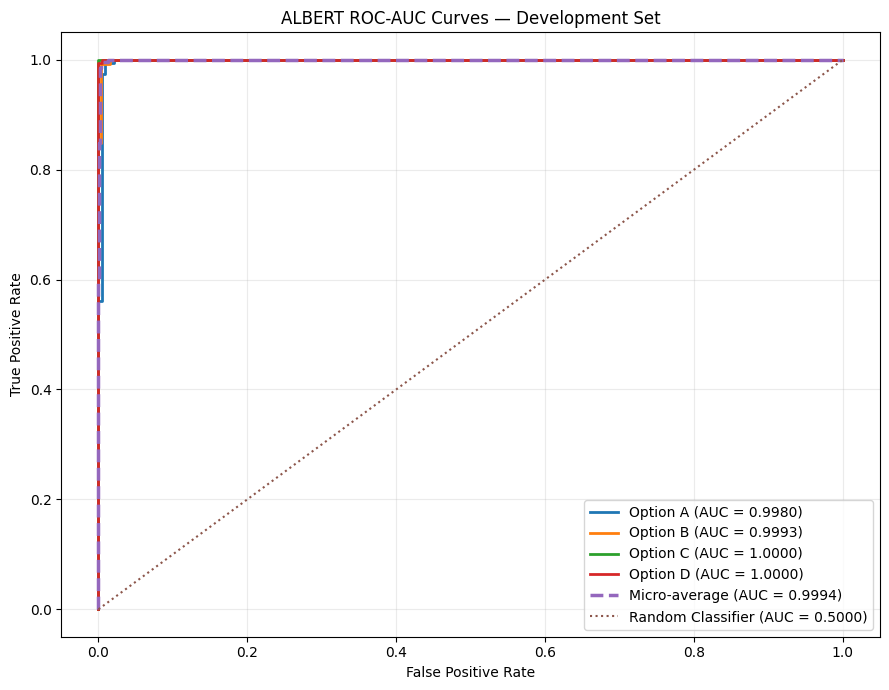


ROC-AUC by option:
Option A: 0.9980
Option B: 0.9993
Option C: 1.0000
Option D: 1.0000


In [14]:
# ==============================================================================
# ADDITION 1: ROC-AUC Curves (Development Set; existing predictions only)
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
roc_labels = ["A", "B", "C", "D"]
plt.figure(figsize=(9, 7))
roc_auc_by_option = {}

for idx, option in enumerate(roc_labels):
    y_true_option = np.asarray(dev_y_actual)[:, idx]
    y_prob_option = np.asarray(dev_y_probs)[:, idx]

    # ROC-AUC requires both positive and negative examples for this option.
    if len(np.unique(y_true_option)) < 2:
        print(f"ROC curve for Option {option} skipped: only one true class is present.")
        continue

    fpr, tpr, _ = roc_curve(y_true_option, y_prob_option)
    option_auc = auc(fpr, tpr)
    roc_auc_by_option[option] = float(option_auc)
    plt.plot(fpr, tpr, linewidth=2, label=f"Option {option} (AUC = {option_auc:.4f})")

# Micro-average ROC curve across all four binary option decisions.
y_true_flat = np.asarray(dev_y_actual).ravel()
y_prob_flat = np.asarray(dev_y_probs).ravel()
if len(np.unique(y_true_flat)) == 2:
    micro_fpr, micro_tpr, _ = roc_curve(y_true_flat, y_prob_flat)
    micro_auc = auc(micro_fpr, micro_tpr)
    plt.plot(
        micro_fpr, micro_tpr, linestyle="--", linewidth=2.5,
        label=f"Micro-average (AUC = {micro_auc:.4f})"
    )
    print(f"Micro-average ROC-AUC: {micro_auc:.4f}")
else:
    micro_auc = float("nan")
    print("Micro-average ROC-AUC could not be calculated: only one true class is present.")

plt.plot([0, 1], [0, 1], linestyle=":", linewidth=1.5, label="Random Classifier (AUC = 0.5000)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ALBERT ROC-AUC Curves — Development Set")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("\nROC-AUC by option:")
for option in roc_labels:
    if option in roc_auc_by_option:
        print(f"Option {option}: {roc_auc_by_option[option]:.4f}")


In [15]:
# ==============================================================================
# ADDITION 2: Matthews Correlation Coefficient (MCC)
# ==============================================================================
from sklearn.metrics import matthews_corrcoef

mcc_y_true = np.asarray(dev_y_actual).ravel()
mcc_y_pred = np.asarray(dev_y_pred).ravel()
overall_mcc = matthews_corrcoef(mcc_y_true, mcc_y_pred)

print("Matthews Correlation Coefficient (MCC)")
print("=" * 50)
print(f"Overall decision-level MCC (all four options): {overall_mcc:.4f}")

mcc_by_option = {}
for idx, option in enumerate(["A", "B", "C", "D"]):
    option_mcc = matthews_corrcoef(
        np.asarray(dev_y_actual)[:, idx],
        np.asarray(dev_y_pred)[:, idx]
    )
    mcc_by_option[option] = float(option_mcc)
    print(f"Option {option} MCC: {option_mcc:.4f}")

macro_mcc = float(np.mean(list(mcc_by_option.values())))
print(f"Macro-average MCC across options: {macro_mcc:.4f}")


Matthews Correlation Coefficient (MCC)
Overall decision-level MCC (all four options): 0.9948
Option A MCC: 0.9896
Option B MCC: 0.9893
Option C MCC: 1.0000
Option D MCC: 1.0000
Macro-average MCC across options: 0.9947
